# Analyse

Le fichier `erp_business_partners.csv` contient les partenaires de Meridian : fournisseurs, clients, transporteurs et prestataires. Pour chacun on a son numéro d'enregistrement officiel, ses régions de facturation et de livraison, sa devise, ses conditions de paiement, son statut, sa classe de risque et sa date d'arrivée.

---
## Configuration

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Racine du projet = le premier dossier parent qui contient data/logistics
project_root = next(
	(path for path in [Path.cwd(), *Path.cwd().parents]
	 if (path / "data" / "logistics").is_dir()),
	Path.cwd(),
)
# Le dossier utils peut être à la racine ou dans un sous-dossier (ex. notebooks/utils)
dossier_utils = next(
	(p for p in [project_root, *project_root.glob("*"), *project_root.glob("*/*")]
	 if (p / "utils" / "variable_analysis.py").is_file()),
	None,
)
if dossier_utils is None:
	raise FileNotFoundError(f"Dossier utils introuvable sous {project_root}")
if str(dossier_utils) not in sys.path:
	sys.path.insert(0, str(dossier_utils))

from utils.variable_analysis import analyser_variables
from utils.correlation_matrices import matrice_correlation, matrice_cramer

DATA = project_root / "data" / "logistics"
pd.set_option("display.width", 200)

---
## 1. Découverte de la table

### 1.1 Lecture brute et dictionnaire des données

In [2]:
brut = pd.read_csv(DATA / "erp_business_partners.csv", dtype=str, keep_default_na=False)
print("Dimensions brutes :", brut.shape)

dico = pd.read_csv(project_root / "data" / "data_dictionary.csv")
dico = dico[dico.iloc[:, 2] == "erp_business_partners.csv"].iloc[:, 3:].reset_index(drop=True)
dico.columns = ["variable", "type_dictionnaire", "role_cle", "description", "exemple"]
dico

Dimensions brutes : (80, 11)


,variable,type_dictionnaire,role_cle,description,exemple
0,partner_code,identifier,primary_or_composite_key,ERP-local business-partner code.,BP-30001
1,partner_name,categorical_or_text,non_key,Partner name.,Marula Cold Store Cooperative
2,partner_role,categorical_or_text,non_key,Partner role.,supplier_customer
3,external_registration_number,identifier,non_key,External registration number.,REG-AVL-20012
4,billing_region,categorical_or_text,non_key,Billing region.,Avelora Federation
5,shipping_region,categorical_or_text,non_key,Shipping region.,Eastern Avelora Agricultural Cluster
6,default_currency,categorical_or_text,non_key,Default currency.,AVL
7,payment_terms,categorical_or_text,non_key,Payment terms.,NET45
8,partner_status,categorical_or_text,non_key,Partner status.,active
9,risk_class,categorical_or_text,non_key,Risk class.,review


In [3]:
brut.head(8)

,partner_code,partner_name,partner_role,external_registration_number,billing_region,shipping_region,default_currency,payment_terms,partner_status,risk_class,onboarding_date
0,BP-30001,Marula Cold Store Cooperative,supplier_customer,REG-AVL-20012,Avelora Federation,Eastern Avelora Agricultural Cluster,AVL,NET45,active,review,2001-02-01
1,BP-30002,Blue Heron Monitoring Cooperative,customer,REG-KNT-20037,Kintara Republic,Kintara Karst Cluster,KRN,NET45,active,standard,2012-03-01
2,BP-30003,Orra Technical Services,supplier,REG-AVL-20022,Avelora Federation,Eastern Avelora Agricultural Cluster,AVL,PUBLIC30,active,review,2008-04-01
3,BP-30004,Common Ground Climate Forum,service_partner,REG-VLN-01008,Valenne Republic,Valenne Central District,VLN,PREPAID,active,review,2014-05-01
4,BP-30005,Warden Medical Ventures,service_partner,REG-VLN-01016,Valenne Republic,Valenne Republic,VLN,PREPAID,inactive,standard,2013-06-01
5,BP-30006,Avelora Food Standards Office,customer,,Avelora Federation,Eastern Avelora Agricultural Cluster,AVL,NET15,active,standard,2013-07-01
6,BP-30007,Helix Legal and Compliance,service_partner,REG-NDH-01012,Nordhaven Union,Nordhaven Maritime District,NDH,NET45,active,standard,2013-08-01
7,BP-30008,Riverstone Waste Management,supplier,REG-AVL-20036,Avelora Federation,Eastern Avelora Agricultural Cluster,AVL,PUBLIC30,active,low,2019-09-01


Ici une ligne correspond à un partenaire (une organisation) tel qu'il est enregistré dans l'ERP. On a 80 partenaires et 11 colonnes. Ce n'est donc pas une table d'événements comme les réceptions, mais une table de référence qui décrit des acteurs qu'on retrouve dans les autres tables.

Comme les données viennent de l'ERP de Meridian, le rôle, le risque et le statut correspondent à ce que Meridian dit de ses partenaires, pas forcément à la réalité. La clé est `partner_code` (de `BP-30001` à `BP-30080`), et `external_registration_number` est le numéro officiel de l'organisation, ce qui permet de faire le lien avec le registre public (`registered_entities.csv`).

On remarque tout de suite que `shipping_region` mélange des districts (*Eastern Avelora Agricultural Cluster*) et des pays (*Valenne Republic*).

### 1.2 Type de chaque colonne

On regarde pour chaque colonne le nombre de valeurs différentes, les vides et quelques exemples.

In [4]:
apercu = pd.DataFrame({
    "valeurs_distinctes": brut.nunique(),
    "vides": (brut.apply(lambda s: s.str.strip()) == "").sum(),
    "exemples": brut.apply(lambda s: list(s.drop_duplicates().head(5))),
})
apercu

,valeurs_distinctes,vides,exemples
partner_code,80,0,"[BP-30001, BP-30002, BP-30003, BP-30004, BP-30..."
partner_name,80,0,"[Marula Cold Store Cooperative, Blue Heron Mon..."
partner_role,6,0,"[supplier_customer, customer, supplier, servic..."
external_registration_number,67,14,"[REG-AVL-20012, REG-KNT-20037, REG-AVL-20022, ..."
billing_region,6,1,"[Avelora Federation, Kintara Republic, Valenne..."
shipping_region,10,0,"[Eastern Avelora Agricultural Cluster, Kintara..."
default_currency,5,0,"[AVL, KRN, VLN, NDH, TMB]"
payment_terms,5,0,"[NET45, PUBLIC30, PREPAID, NET15, NET30]"
partner_status,2,0,"[active, inactive]"
risk_class,4,0,"[review, standard, low, elevated]"


| Colonne | Type | Remarque |
|---|---|---|
| `partner_code` | identifiant | 80 valeurs, dans l'ordre de saisie |
| `partner_name` | identifiant (texte) | 80 noms différents |
| `partner_role` | catégorie | 6 libellés, dont une variante de majuscule |
| `external_registration_number` | identifiant au format `REG-<pays>-<série><n°>` | 14 vides |
| `billing_region` | catégorie (pays) | 5 pays et 1 vide |
| `shipping_region` | catégorie | 10 valeurs, pays et districts mélangés |
| `default_currency` | catégorie | 5 devises |
| `payment_terms` | catégorie en partie ordonnable par délai (`PREPAID` < `NET15` < `NET30` / `PUBLIC30` < `NET45`) | 5 valeurs |
| `partner_status` | oui / non (`active` / `inactive`) | |
| `risk_class` | catégorie ordonnée (`low` < `standard` < `review` < `elevated`) | on peut la traiter comme un rang |
| `onboarding_date` | date | une valeur dans un autre format |

Il n'y a aucune colonne numérique au départ. Pour les statistiques on utilisera donc la date, les catégories ordonnées transformées en rangs, et l'activité des partenaires qu'on va calculer à partir des autres tables.

---
## 2. Nettoyage

Même ordre que d'habitude : doublons, formats, libellés, puis valeurs manquantes et bizarres. On garde la table brute `brut` et on travaille sur une copie `bp`.

### 2.1 Doublons

On cherche les lignes en double, mais aussi les codes ou les noms en double (un partenaire saisi deux fois) et les colonnes qui répètent la même information.

In [5]:
bp = brut.copy()
print(f"Doublons exacts : {bp.duplicated().sum()}")
print(f"Doublons de partner_code : {bp.partner_code.duplicated().sum()}")
nom_normalise = bp.partner_name.str.strip().str.replace(r"\s+", " ", regex=True).str.lower()
print(f"Doublons de nom (après normalisation des espaces et de la casse) : {nom_normalise.duplicated().sum()}")
reg = bp.external_registration_number.replace("", np.nan)
print(f"Doublons de numéro d'enregistrement externe (hors vides) : {reg.dropna().duplicated().sum()}")

Doublons exacts : 0
Doublons de partner_code : 0
Doublons de nom (après normalisation des espaces et de la casse) : 0
Doublons de numéro d'enregistrement externe (hors vides) : 0


In [6]:
# Colonnes : région de facturation, devise et pays du numéro d'enregistrement disent-ils la même chose ?
print(pd.crosstab(bp.billing_region.replace("", "(vide)"), bp.default_currency))

pays_reg = bp.external_registration_number.str.extract(r"^REG-([A-Z]{3})-")[0]
devise_du_pays = {"AVL": "AVL", "KNT": "KRN", "VLN": "VLN", "NDH": "NDH", "TMB": "TMB"}
concorde = pays_reg.map(devise_du_pays) == bp.default_currency
print(f"\nPays du numéro d'enregistrement cohérent avec la devise : {concorde[pays_reg.notna()].mean():.0%} "
      f"({pays_reg.notna().sum()} partenaires enregistrés)")

default_currency      AVL  KRN  NDH  TMB  VLN
billing_region                               
(vide)                  0    1    0    0    0
Avelora Federation     16    0    0    0    0
Kintara Republic        0   11    0    0    0
Nordhaven Union         0    0   12    0    0
Tembara Commonwealth    0    0    0   13    0
Valenne Republic        0    0    0    0   27

Pays du numéro d'enregistrement cohérent avec la devise : 100% (66 partenaires enregistrés)


On ne trouve aucun doublon : pas de ligne répétée, et aucun code, nom ou numéro en double.

Par contre, certaines colonnes disent la même chose. Le pays de facturation et la devise vont toujours ensemble (chaque pays a sa devise), et le pays qui apparaît dans le numéro d'enregistrement (`REG-KNT-...`) correspond aussi à la devise pour les 66 partenaires qui ont un numéro. On garde quand même toutes les colonnes, parce que cette redondance va nous servir à retrouver le pays manquant (partie 2.4). Il faudra juste éviter de compter deux fois la même information plus loin.

### 2.2 Formats

On vérifie la date d'arrivée, les espaces dans les noms et le niveau de détail de la région de livraison.

In [7]:
# --- Dates
iso = bp.onboarding_date.str.fullmatch(r"\d{4}-\d{2}-\d{2}")
print(f"Dates ISO : {iso.sum()} / {len(bp)} ; autres :",
      bp.loc[~iso, ["partner_code", "onboarding_date"]].values.tolist())
print("Jours du mois présents dans les dates ISO :", sorted(bp.onboarding_date[iso].str[-2:].unique()))

# Le mois d'entrée semble suivre le numéro du partenaire : on le vérifie sur les dates ISO
numero = bp.partner_code.str[3:].astype(int)
mois_iso = bp.onboarding_date[iso].str[5:7].astype(int)
mois_attendu = numero % 12 + 1
print(f"Mois = (numéro mod 12) + 1 pour {(mois_iso == mois_attendu[iso]).mean():.0%} des dates ISO")
print("Pour la date non ISO, mois attendu :", mois_attendu[~iso].tolist())

Dates ISO : 79 / 80 ; autres : [['BP-30021', '01/10/2003']]
Jours du mois présents dans les dates ISO : ['01']
Mois = (numéro mod 12) + 1 pour 100% des dates ISO
Pour la date non ISO, mois attendu : [10]


In [8]:
bp["onboarding_date"] = pd.to_datetime(bp.onboarding_date, format="%Y-%m-%d", errors="coerce").fillna(
    pd.to_datetime(bp.onboarding_date, format="%d/%m/%Y", errors="coerce"))
print("Dates non converties :", bp.onboarding_date.isna().sum())
print("Période :", bp.onboarding_date.min().date(), "→", bp.onboarding_date.max().date())

# --- Espaces dans les noms
mal_espaces = bp.partner_name != bp.partner_name.str.strip().str.replace(r"\s+", " ", regex=True)
print("\nNoms avec des espaces en trop :", bp.loc[mal_espaces, "partner_name"].map(repr).tolist())
for c in bp.columns:
    if bp[c].dtype == object:
        bp[c] = bp[c].str.strip().str.replace(r"\s+", " ", regex=True)

Dates non converties : 0
Période : 1998-04-01 → 2019-09-01

Noms avec des espaces en trop : ["'  Tembara  Customs  Coordination  Unit '"]


In [9]:
# --- Niveau de détail de la région de livraison : pays ou district ?
pays = set(bp.billing_region.replace("", np.nan).dropna())
bp["shipping_niveau"] = np.where(bp.shipping_region.isin(pays), "pays", "district")
print(bp.shipping_niveau.value_counts().to_string())
print()
print(pd.crosstab(bp.shipping_region, bp.billing_region.replace("", "(vide)")).to_string())

shipping_niveau
district    66
pays        14

billing_region                        (vide)  Avelora Federation  Kintara Republic  Nordhaven Union  Tembara Commonwealth  Valenne Republic
shipping_region                                                                                                                            
Avelora Federation                         0                   3                 0                0                     0                 0
Eastern Avelora Agricultural Cluster       0                  13                 0                0                     0                 0
Kintara Karst Cluster                      1                   0                 8                0                     0                 0
Kintara Republic                           0                   0                 3                0                     0                 0
Nordhaven Maritime District                0                   0                 0                9              

Une seule date ambiguë, corrigée grâce au numéro du partenaire. Le jour et le mois sont fixés par le numéro, donc seule l'année compte.

### 2.3 Libellés des catégories

In [10]:
categorielles = ["partner_role", "billing_region", "shipping_region", "default_currency",
                 "payment_terms", "partner_status", "risk_class"]
for c in categorielles:
    print(f"{c} : {bp[c].value_counts().to_dict()}")

partner_role : {'customer': 32, 'service_partner': 19, 'supplier': 13, 'carrier': 9, 'supplier_customer': 6, 'Supplier': 1}
billing_region : {'Valenne Republic': 27, 'Avelora Federation': 16, 'Tembara Commonwealth': 13, 'Nordhaven Union': 12, 'Kintara Republic': 11, '': 1}
shipping_region : {'Valenne Central District': 23, 'Eastern Avelora Agricultural Cluster': 13, 'Tembara Coastal Cluster': 12, 'Kintara Karst Cluster': 9, 'Nordhaven Maritime District': 9, 'Valenne Republic': 4, 'Kintara Republic': 3, 'Nordhaven Union': 3, 'Avelora Federation': 3, 'Tembara Commonwealth': 1}
default_currency : {'VLN': 27, 'AVL': 16, 'TMB': 13, 'KRN': 12, 'NDH': 12}
payment_terms : {'PUBLIC30': 20, 'NET30': 17, 'NET45': 15, 'PREPAID': 15, 'NET15': 13}
partner_status : {'active': 72, 'inactive': 8}
risk_class : {'standard': 37, 'review': 19, 'low': 15, 'elevated': 9}


In [11]:
bp["partner_role"] = bp.partner_role.str.lower()
print("partner_role après harmonisation :", bp.partner_role.value_counts().to_dict())

partner_role après harmonisation : {'customer': 32, 'service_partner': 19, 'supplier': 14, 'carrier': 9, 'supplier_customer': 6}


Le seul libellé à corriger est `Supplier` (`BP-30069`), qu'on passe en `supplier`. Il reste 5 rôles : client 32, prestataire de services 19, fournisseur 14, transporteur 9, fournisseur-client 6. Les autres colonnes n'ont pas de variante. On a hésité pour `PUBLIC30` et `NET30`, qui ont le même délai de 30 jours, mais ce ne sont pas les mêmes conditions donc on garde les deux.

### 2.4 Valeurs manquantes et valeurs bizarres

In [12]:
bp = bp.replace("", np.nan)
print("Valeurs manquantes par colonne :")
print(bp.isna().sum()[bp.isna().sum() > 0].to_string())
print()
print(bp[bp.billing_region.isna()][["partner_code", "partner_name", "billing_region", "shipping_region",
                                    "default_currency", "external_registration_number"]].to_string())

Valeurs manquantes par colonne :
external_registration_number    14
billing_region                   1

   partner_code                   partner_name billing_region        shipping_region default_currency external_registration_number
28     BP-30029  Kestrel Conservation Services            NaN  Kintara Karst Cluster              KRN                REG-KNT-20014


In [13]:
# billing_region : la devise détermine le pays dans 100 % des autres lignes -> on peut l'inférer
pays_de_devise = bp.dropna(subset=["billing_region"]).groupby("default_currency").billing_region.first()
bp["billing_region"] = bp.billing_region.fillna(bp.default_currency.map(pays_de_devise))
print("billing_region inférée pour BP-30029 :", bp.loc[bp.partner_code == "BP-30029", "billing_region"].item())

# external_registration_number : qui n'a pas de numéro ?
sans_reg = bp[bp.external_registration_number.isna()]
print(f"\nPartenaires sans numéro d'enregistrement : {len(sans_reg)}")
print("Rôle :", sans_reg.partner_role.value_counts().to_dict())
print(sans_reg.partner_name.tolist())

billing_region inférée pour BP-30029 : Kintara Republic

Partenaires sans numéro d'enregistrement : 14
Rôle : {'customer': 14}
['Avelora Food Standards Office', 'Tembara Coastal Administration', 'Kintara Cave and Pollinator Authority', 'Orison Medical Audit Board', 'Kintara Emergency Response Office', 'Office of the Kintara Chancellor', 'Tembara Biodiversity Service', 'Tembara Customs Coordination Unit', 'Kintara Rural Transport Board', 'Nordhaven Maritime Safety Agency', 'Avelora Ministry of Strategic Resources', 'Avelora Agricultural Resilience Agency', 'Valenne Public Procurement Authority', 'Avelora Council of State']


In [14]:
# Variables dérivées du numéro d'enregistrement : pays et série (01xxx ou 20xxx)
bp["reg_serie"] = bp.external_registration_number.str.extract(r"-(\d{2})\d{3}$")[0].fillna("aucun")
print(pd.crosstab(bp.reg_serie, bp.partner_role, margins=True).to_string())

# La série 01 correspond-elle aux entités du registre public (data/public_records) ?
registre = pd.read_csv(project_root / "data" / "public_records" / "registered_entities.csv")
dans_registre = bp.external_registration_number.isin(registre.registration_number)
print("\nPartenaires présents dans le registre public, par série :")
print(pd.crosstab(bp.reg_serie, dans_registre).to_string())

partner_role  carrier  customer  service_partner  supplier  supplier_customer  All
reg_serie                                                                         
01                  3         9               10         0                  2   24
20                  6         9                9        14                  4   42
aucun               0        14                0         0                  0   14
All                 9        32               19        14                  6   80

Partenaires présents dans le registre public, par série :
external_registration_number  False  True 
reg_serie                                 
01                                0     24
20                               42      0
aucun                            14      0


In [15]:
# Valeurs aberrantes : la seule variable continue est la date d'entrée en relation
annee = bp.onboarding_date.dt.year
q1, q3 = annee.quantile([.25, .75])
print(f"Années : Q1 = {q1:.0f}, Q3 = {q3:.0f}, bornes de Tukey = [{q1 - 1.5*(q3-q1):.0f} ; {q3 + 1.5*(q3-q1):.0f}]")
print("Années hors bornes :", int(((annee < q1 - 1.5*(q3-q1)) | (annee > q3 + 1.5*(q3-q1))).sum()))

Années : Q1 = 2003, Q3 = 2012, bornes de Tukey = [1989 ; 2026]
Années hors bornes : 0


On complète un pays grâce à la devise. Les 14 partenaires sans numéro sont des organismes publics. Les numéros de la série 01 sont exactement les 24 entreprises du registre public.

### 2.5 Ce que font les partenaires dans les autres tables

Pour mieux comprendre les partenaires, on compte pour chacun le nombre de réceptions qu'il a fournies (`goods_receipts`) et le nombre de sites qu'il exploite (`erp_facilities`). Dans ces tables on enlève seulement les doublons.

In [16]:
gr = pd.read_csv(DATA / "goods_receipts.csv", dtype=str).drop_duplicates()
fa = pd.read_csv(DATA / "erp_facilities.csv", dtype=str)

bp["nb_receptions_fournies"] = bp.partner_code.map(gr.supplier_partner_code.value_counts()).fillna(0).astype(int)
bp["nb_sites_exploites"] = bp.partner_code.map(fa.operating_partner_code.value_counts()).fillna(0).astype(int)
bp["anciennete_ans"] = ((pd.Timestamp("2025-06-30") - bp.onboarding_date).dt.days / 365.25).round(1)

print("Partenaires sans aucune réception fournie :", int((bp.nb_receptions_fournies == 0).sum()))
print("Partenaires exploitant au moins un site :", int((bp.nb_sites_exploites > 0).sum()))
print("\nRéceptions fournies selon le rôle déclaré :")
print(bp.groupby("partner_role").nb_receptions_fournies.agg(["count", "sum", "mean", "max"]).round(1).to_string())
print("\nLes 6 premiers fournisseurs :")
print(bp.nlargest(6, "nb_receptions_fournies")[["partner_code", "partner_name", "partner_role",
      "risk_class", "nb_receptions_fournies", "nb_sites_exploites"]].to_string(index=False))

Partenaires sans aucune réception fournie : 11
Partenaires exploitant au moins un site : 26

Réceptions fournies selon le rôle déclaré :
                   count  sum  mean  max
partner_role                            
carrier                9  154  17.1  109
customer              32  169   5.3   25
service_partner       19  131   6.9   13
supplier              14  101   7.2   14
supplier_customer      6   55   9.2   12

Les 6 premiers fournisseurs :
partner_code                       partner_name      partner_role risk_class  nb_receptions_fournies  nb_sites_exploites
    BP-30078              Meridian BioLogistics           carrier   standard                     109                   4
    BP-30056 Horizon Field Research Cooperative          customer   standard                      25                   0
    BP-30080      Garnet Scientific Instruments          supplier   standard                      14                   0
    BP-30009       Lantern Investigative Bureau   service_par

In [17]:
# Partenaires inactifs : fournissent-ils encore des réceptions ?
gr["receipt_date"] = pd.to_datetime(gr.receipt_date, format="mixed", errors="coerce")
derniere = gr.groupby("supplier_partner_code").receipt_date.max()
bp["derniere_reception"] = bp.partner_code.map(derniere)
print(bp[bp.partner_status == "inactive"][["partner_code", "partner_name", "partner_role",
      "nb_receptions_fournies", "derniere_reception"]].to_string(index=False))

partner_code                         partner_name      partner_role  nb_receptions_fournies derniere_reception
    BP-30005              Warden Medical Ventures   service_partner                       6         2023-09-19
    BP-30013               Vann Maritime Advisory   service_partner                       5         2025-05-21
    BP-30022        Varlan Natural History Circle          customer                      10         2025-06-04
    BP-30026 Valenne Industrial Supply Consortium          customer                       7         2024-07-06
    BP-30034    Commonway Legal Registry Services   service_partner                       7         2025-05-24
    BP-30038                  Vosmere Biotechnics supplier_customer                      10         2025-06-11
    BP-30058       Marot Ecological Policy Office   service_partner                       7         2025-06-01
    BP-30059             Bell Conservation Survey          customer                      13         2025-05-27


Le rôle déclaré ne colle pas avec l'activité : Meridian, déclarée transporteur, est le premier fournisseur (109 réceptions), et des clients livrent plus que les vrais fournisseurs. Les 8 partenaires inactifs livrent encore.

### 2.6 Table nettoyée

In [18]:
print("Dimensions finales :", bp.shape)
print("Valeurs manquantes :", bp.isna().sum()[bp.isna().sum() > 0].to_dict())
bp.head()

Dimensions finales : (80, 17)
Valeurs manquantes : {'external_registration_number': 14, 'derniere_reception': 11}


,partner_code,partner_name,partner_role,external_registration_number,billing_region,shipping_region,default_currency,payment_terms,partner_status,risk_class,onboarding_date,shipping_niveau,reg_serie,nb_receptions_fournies,nb_sites_exploites,anciennete_ans,derniere_reception
0,BP-30001,Marula Cold Store Cooperative,supplier_customer,REG-AVL-20012,Avelora Federation,Eastern Avelora Agricultural Cluster,AVL,NET45,active,review,2001-02-01,district,20,12,1,24.4,2025-06-01
1,BP-30002,Blue Heron Monitoring Cooperative,customer,REG-KNT-20037,Kintara Republic,Kintara Karst Cluster,KRN,NET45,active,standard,2012-03-01,district,20,7,0,13.3,2022-11-16
2,BP-30003,Orra Technical Services,supplier,REG-AVL-20022,Avelora Federation,Eastern Avelora Agricultural Cluster,AVL,PUBLIC30,active,review,2008-04-01,district,20,4,0,17.2,2021-06-05
3,BP-30004,Common Ground Climate Forum,service_partner,REG-VLN-01008,Valenne Republic,Valenne Central District,VLN,PREPAID,active,review,2014-05-01,district,01,0,0,11.2,NaT
4,BP-30005,Warden Medical Ventures,service_partner,REG-VLN-01016,Valenne Republic,Valenne Republic,VLN,PREPAID,inactive,standard,2013-06-01,pays,01,6,0,12.1,2023-09-19


Récapitulatif du nettoyage :

| Étape | Ce qu'on a fait | Résultat |
|---|---|---|
| Doublons | aucun ; devise, pays et numéro concordent à 100 % | 80 lignes |
| Formats | 1 date lue en jour/mois ; espaces retirés ; niveau de la région noté | `shipping_niveau` |
| Libellés | `Supplier` → `supplier` | 5 rôles |
| Manquants | 1 pays complété grâce à la devise ; 14 numéros absents gardés (organismes publics) | `reg_serie` (`01`, `20`, `aucun`) |
| Valeurs bizarres | aucune | |
| Nouvelles colonnes | activité dans les réceptions et les sites | réceptions fournies, sites exploités, ancienneté, dernière réception |

On a 80 lignes et 17 colonnes. Les seuls vides qui restent sont voulus : les numéros des 14 organismes publics et la dernière réception des 11 partenaires qui n'ont jamais livré.

In [19]:
# On enregistre la table nettoyée pour pouvoir la réutiliser sans relancer le nettoyage
CLEAN = DATA / "clean"
CLEAN.mkdir(exist_ok=True)
bp.to_csv(CLEAN / "erp_business_partners_clean.csv", index=False)
print("Table enregistrée :", (CLEAN / "erp_business_partners_clean.csv").relative_to(project_root), bp.shape)

Table enregistrée : data\logistics\clean\erp_business_partners_clean.csv (80, 17)


---
## 3. Statistiques descriptives

Moyenne, écart-type, médiane, quartiles et histogramme pour les nombres, répartition pour les catégories. On ne regarde pas les identifiants.


=== partner_role  [catégorielle] ===
  Effectif : 80  (manquants : 0, modalités : 5)
  Mode : customer (40.0 %)
                   effectif     %
partner_role                     
customer                 32  40.0
service_partner          19  23.8
supplier                 14  17.5
carrier                   9  11.2
supplier_customer         6   7.5


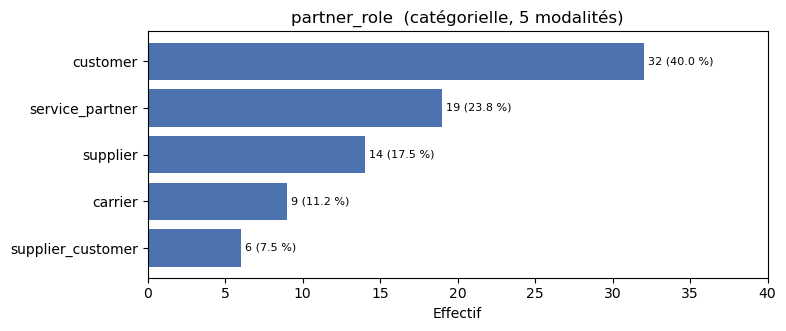


=== billing_region  [catégorielle] ===
  Effectif : 80  (manquants : 0, modalités : 5)
  Mode : Valenne Republic (33.8 %)
                      effectif     %
billing_region                      
Valenne Republic            27  33.8
Avelora Federation          16  20.0
Tembara Commonwealth        13  16.2
Kintara Republic            12  15.0
Nordhaven Union             12  15.0


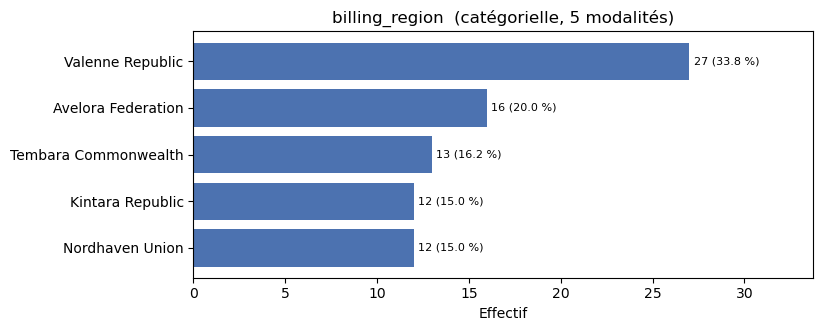


=== shipping_niveau  [catégorielle] ===
  Effectif : 80  (manquants : 0, modalités : 2)
  Mode : district (82.5 %)
                 effectif     %
shipping_niveau                
district               66  82.5
pays                   14  17.5


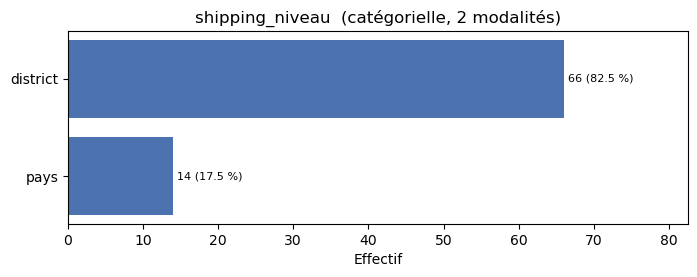


=== payment_terms  [catégorielle] ===
  Effectif : 80  (manquants : 0, modalités : 5)
  Mode : PUBLIC30 (25.0 %)
               effectif     %
payment_terms                
PUBLIC30             20  25.0
NET30                17  21.2
NET45                15  18.8
PREPAID              15  18.8
NET15                13  16.2


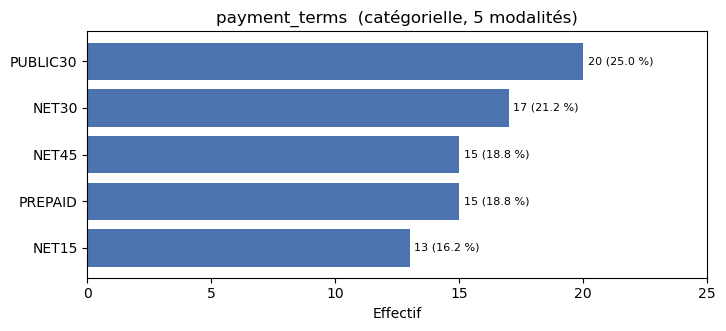


=== partner_status  [catégorielle] ===
  Effectif : 80  (manquants : 0, modalités : 2)
  Mode : active (90.0 %)
                effectif     %
partner_status                
active                72  90.0
inactive               8  10.0


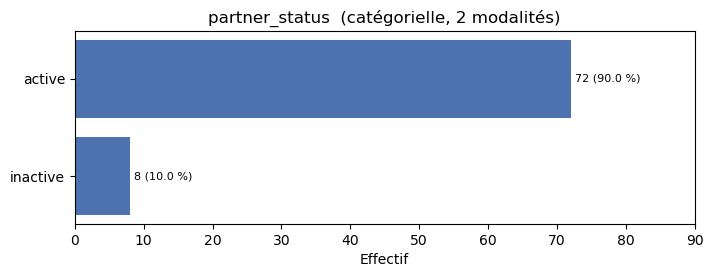


=== risk_class  [catégorielle] ===
  Effectif : 80  (manquants : 0, modalités : 4)
  Mode : standard (46.2 %)
            effectif     %
risk_class                
standard          37  46.2
review            19  23.8
low               15  18.8
elevated           9  11.2


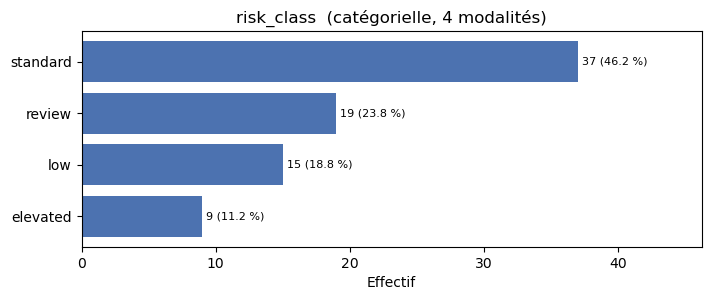


=== reg_serie  [catégorielle] ===
  Effectif : 80  (manquants : 0, modalités : 3)
  Mode : 20 (52.5 %)
           effectif     %
reg_serie                
20               42  52.5
01               24  30.0
aucun            14  17.5


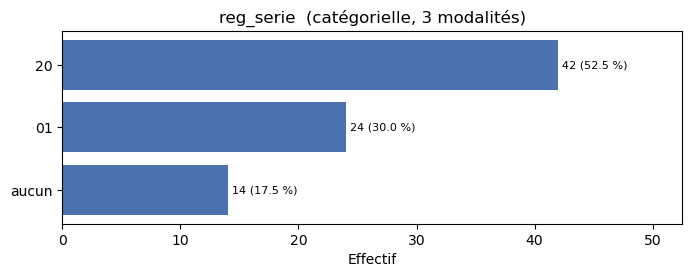


=== onboarding_date  [date] ===
  Effectif : 80  (manquants : 0, valeurs distinctes : 65)
  Moyenne ± écart-type : 2008-03-09 ± 2073.1 jours
  Médiane [min ; Q1 - Q3 ; max] : 2008-08-16 [1998-04-01 ; 2003-10-01 - 2013-01-15 ; 2019-09-01]
  Asymétrie : -0.02


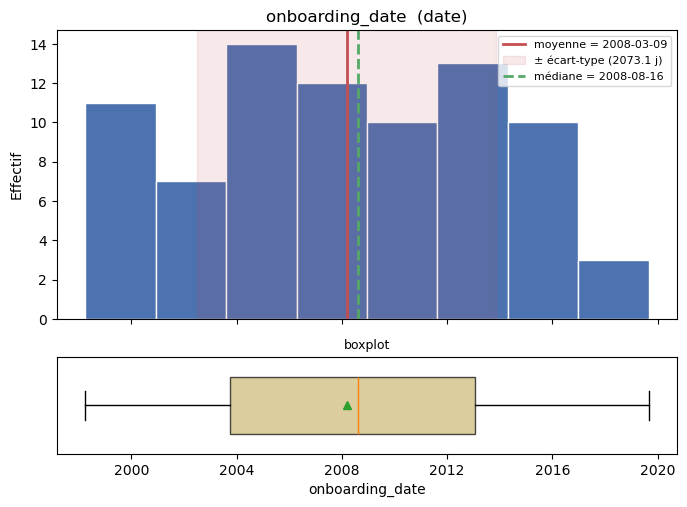


=== nb_receptions_fournies  [discrète] ===
  Effectif : 80  (manquants : 0, valeurs distinctes : 17)
  Moyenne ± écart-type : 7.625 ± 12.271
  Médiane [min ; Q1 - Q3 ; max] : 7.000 [0.000 ; 3.750 - 9.250 ; 109.000]
  Asymétrie : 7.31


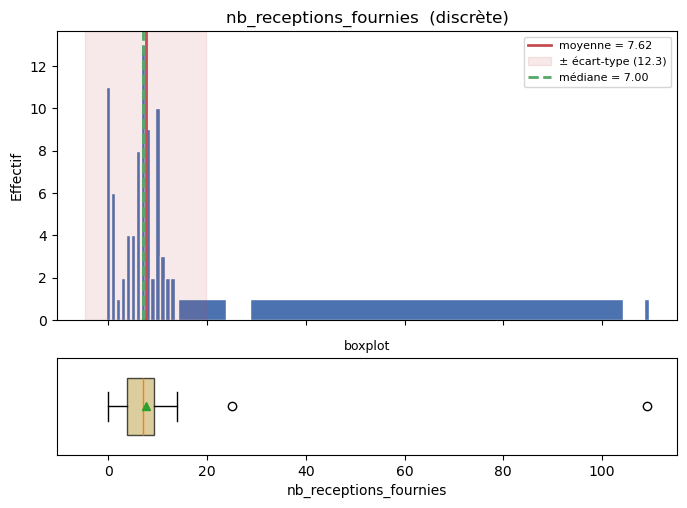


=== nb_sites_exploites  [discrète] ===
  Effectif : 80  (manquants : 0, valeurs distinctes : 4)
  Moyenne ± écart-type : 0.375 ± 0.644
  Médiane [min ; Q1 - Q3 ; max] : 0.000 [0.000 ; 0.000 - 1.000 ; 4.000]
  Asymétrie : 2.67


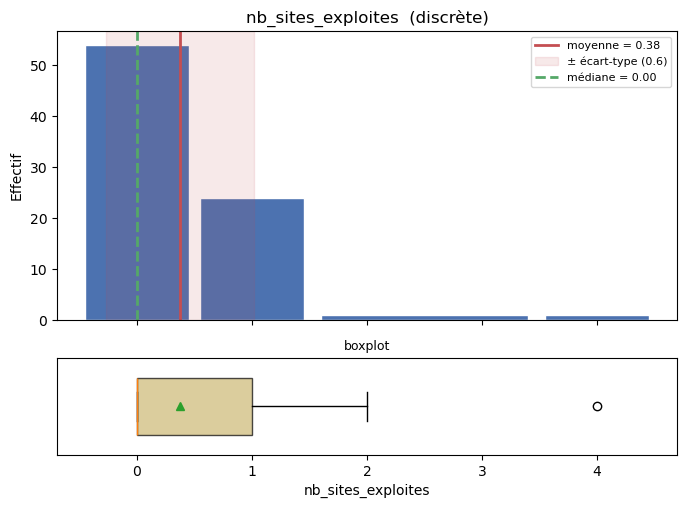

In [20]:
colonnes_univariees = ["partner_role", "billing_region", "shipping_niveau", "payment_terms", "partner_status",
                       "risk_class", "reg_serie", "onboarding_date", "nb_receptions_fournies", "nb_sites_exploites"]
resume = analyser_variables(bp, columns=colonnes_univariees)

In [21]:
# Variables ordinales : ordre logique des modalités (si les valeurs sont ordonnées,
# elles peuvent être traitées comme une variable numérique »)
ordre_risque = ["low", "standard", "review", "elevated"]
delai_paiement = {"PREPAID": 0, "NET15": 15, "NET30": 30, "PUBLIC30": 30, "NET45": 45}
bp["risque_rang"] = bp.risk_class.map({v: i for i, v in enumerate(ordre_risque)})
bp["delai_paiement_jours"] = bp.payment_terms.map(delai_paiement)
print(pd.crosstab(bp.partner_role, bp.risk_class)[ordre_risque].to_string())

risk_class         low  standard  review  elevated
partner_role                                      
carrier              1         6       1         1
customer             7        12       9         4
service_partner      4         8       5         2
supplier             2         8       3         1
supplier_customer    1         3       1         1


Côté rôles, on a 40 % de clients, 23,8 % de prestataires, 17,5 % de fournisseurs, 11,2 % de transporteurs et 7,5 % de fournisseurs-clients. Pour les pays, Valenne arrive en tête avec 33,8 % (c'est le pays du siège de Meridian), puis Avelora 20 %, Tembara 16,2 %, Kintara et Nordhaven 15 % chacun. 90 % des partenaires sont actifs.

Pour le risque, on trouve `standard` 46,2 %, `review` 23,8 %, `low` 18,8 % et `elevated` 11,2 %, donc plus d'un partenaire sur trois est sous surveillance, et ça se répartit à peu près pareil entre les rôles. Les conditions de paiement sont assez équilibrées (entre 16,2 % et 25 %). Pour les numéros, la série 20 représente 52,5 %, la série 01 (registre public) 30 % et les partenaires sans numéro 17,5 %.

Les dates d'arrivée vont d'avril 1998 à septembre 2019 (médiane août 2008) et sont régulières sur 20 ans. Personne n'arrive après 2019, alors que l'activité continue jusqu'en 2025.

Pour l'activité, le nombre de réceptions fournies a une médiane de 7 et une moyenne de 7,6, mais va de 0 à 109 : presque tout le monde fournit quelques réceptions et un seul partenaire en fournit énormément, donc ici c'est la médiane qu'il faut regarder. La plupart des partenaires n'exploitent aucun site, 26 en exploitent un, et Meridian en exploite 4.

---
## 4. Corrélations

Spearman et Pearson sur les nombres et les catégories ordonnées, avec les nuages de points, puis le V de Cramér pour les catégories.

### 4.1 Spearman et Pearson

Variables utilisées (5) : ['onboarding_date (date -> jours)', 'risque_rang (numérique)', 'delai_paiement_jours (numérique)', 'nb_receptions_fournies (numérique)', 'nb_sites_exploites (numérique)']


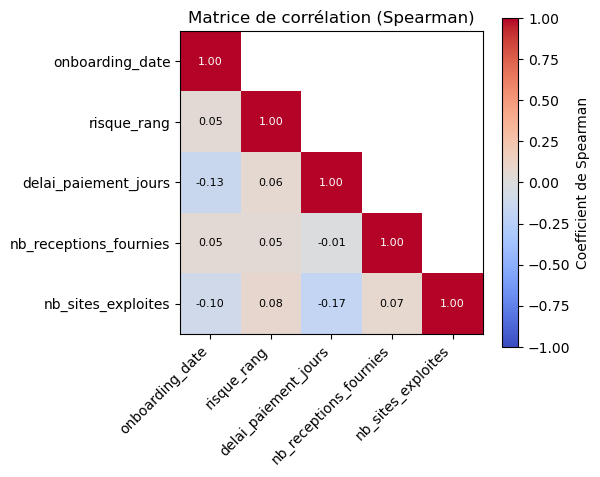


Paires avec |spearman| >= 0.3 :
  aucune


In [22]:
numeriques = ["onboarding_date", "risque_rang", "delai_paiement_jours", "nb_receptions_fournies",
              "nb_sites_exploites"]
spearman = matrice_correlation(bp, columns=numeriques, method="spearman", seuil_paires=0.3)

Variables utilisées (5) : ['onboarding_date (date -> jours)', 'risque_rang (numérique)', 'delai_paiement_jours (numérique)', 'nb_receptions_fournies (numérique)', 'nb_sites_exploites (numérique)']


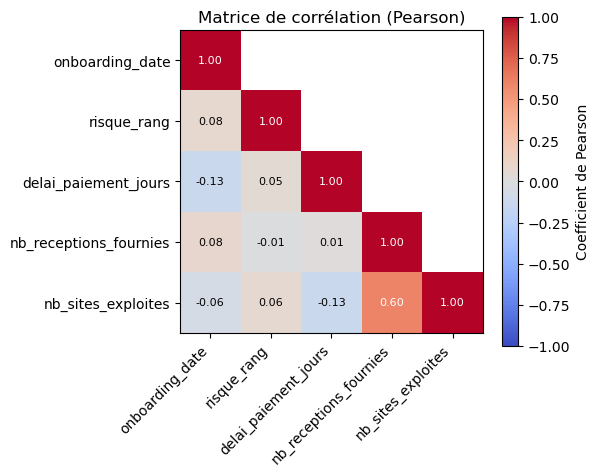


Paires avec |pearson| >= 0.3 :
        variable_1             variable_2   valeur
nb_sites_exploites nb_receptions_fournies 0.601225


In [23]:
pearson = matrice_correlation(bp, columns=numeriques, method="pearson", seuil_paires=0.3)

Paires où Spearman et Pearson diffèrent de plus de 0,15 :
  nb_receptions_fournies - nb_sites_exploites : Spearman 0.07 | Pearson 0.60


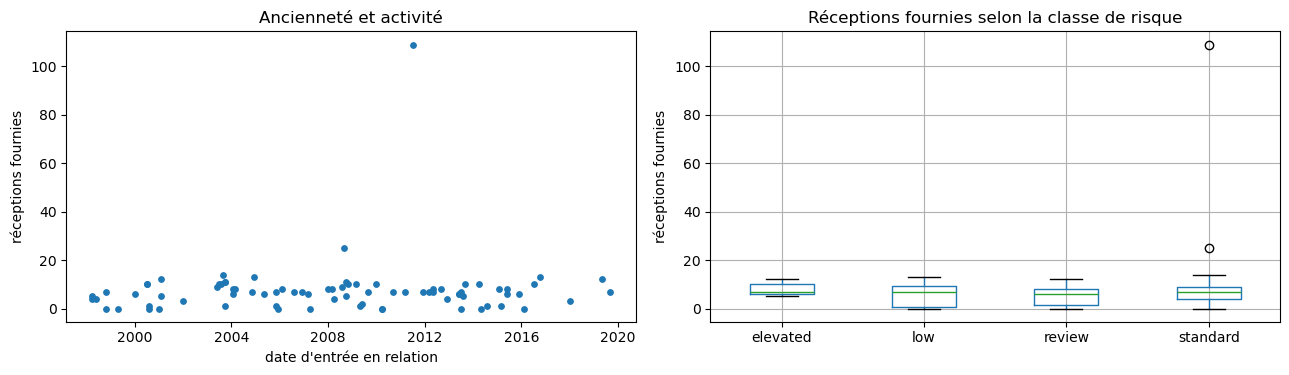

In [24]:
ecart = (spearman - pearson).abs()
print("Paires où Spearman et Pearson diffèrent de plus de 0,15 :")
for i, a in enumerate(ecart.index):
    for b in ecart.columns[i + 1:]:
        if ecart.loc[a, b] > 0.15:
            print(f"  {a} - {b} : Spearman {spearman.loc[a, b]:.2f} | Pearson {pearson.loc[a, b]:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(bp.onboarding_date, bp.nb_receptions_fournies, s=15)
axes[0].set(xlabel="date d'entrée en relation", ylabel="réceptions fournies", title="Ancienneté et activité")
bp.boxplot(column="nb_receptions_fournies", by="risk_class", ax=axes[1], positions=None)
axes[1].set(title="Réceptions fournies selon la classe de risque", xlabel="", ylabel="réceptions fournies")
plt.suptitle("")
plt.tight_layout()
plt.show()

Avec Spearman, aucune paire ne dépasse 0,3 : l'ancienneté, le risque, le délai de paiement et l'activité ne sont pas liés. Avec Pearson, une seule paire ressort, le nombre de sites exploités et le nombre de réceptions (0,60), alors que Spearman ne donne que 0,07 pour la même paire. Le nuage de points montre pourquoi : la corrélation de Pearson vient uniquement de Meridian (4 sites, 109 réceptions), et sans ce point il n'y a plus rien. Le risque n'est pas lié à l'activité non plus.

C'est un bon exemple de Pearson qui se fait piéger par une valeur extrême alors que Spearman, qui travaille sur les rangs, ne l'est pas. C'est pour ça qu'on calcule les deux. Et au passage, le partenaire le plus actif de toute la table est classé en risque `standard`.

### 4.2 Liens entre catégories

Variables catégorielles utilisées (8) : ['partner_role', 'billing_region', 'default_currency', 'shipping_niveau', 'payment_terms', 'partner_status', 'risk_class', 'reg_serie']


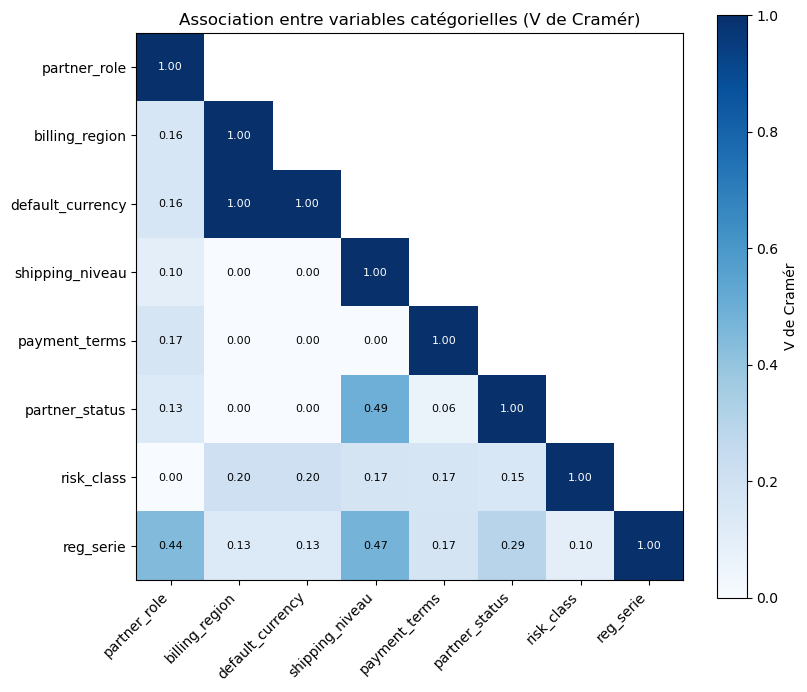


Paires avec |V de Cramér| >= 0.5 :
      variable_1     variable_2  valeur
default_currency billing_region     1.0


In [25]:
nominales = ["partner_role", "billing_region", "default_currency", "shipping_niveau", "payment_terms",
             "partner_status", "risk_class", "reg_serie"]
cramer = matrice_cramer(bp, columns=nominales)

In [26]:
print(pd.crosstab(bp.reg_serie, bp.risk_class)[ordre_risque].to_string())
print()
print(pd.crosstab(bp.partner_role, bp.payment_terms).to_string())

risk_class  low  standard  review  elevated
reg_serie                                  
01            3        12       4         5
20            7        20      11         4
aucun         5         5       4         0

payment_terms      NET15  NET30  NET45  PREPAID  PUBLIC30
partner_role                                             
carrier                2      3      0        3         1
customer               8      8      4        6         6
service_partner        1      2      5        4         7
supplier               0      1      5        2         6
supplier_customer      2      3      1        0         0


À part devise et pays (V = 1), les colonnes sont peu liées. La série 01 est un peu plus souvent en risque élevé (21 % contre 10 %).

---
## 5. Regrouper les partenaires

### 5.1 Profil d'activité de chaque partenaire

La table ne contient presque que des catégories déclarées par Meridian. Pour comparer les partenaires sur ce qu'ils font réellement, on leur construit un profil à partir des autres tables : réceptions fournies et part incomplète, sites livrés, part des livraisons vers le groupe des 10 sites, expéditions envoyées, reçues et transportées. Dans ces tables on fait juste le nettoyage minimum (doublons, espaces, majuscules, dates).

In [27]:
def lire(nom):
    return pd.read_csv(DATA / nom, dtype=str).apply(lambda s: s.str.strip()).drop_duplicates()

def convertir_date(serie):
    # formats rencontrés dans les tables logistiques (voir le notebook des réceptions)
    out = pd.Series(pd.NaT, index=serie.index)
    for fmt in ("%Y-%m-%d", "%Y/%m/%d", "%d/%m/%Y", "%d-%b-%Y"):
        out = out.fillna(pd.to_datetime(serie, format=fmt, errors="coerce"))
    return out

sh = lire("shipments.csv")
sh["dispatch_time"] = pd.to_datetime(sh.dispatch_time, format="mixed", errors="coerce")
po = lire("purchase_order_lines.csv")
gr = lire("goods_receipts.csv")
gr["receipt_date"] = convertir_date(gr.receipt_date)
gr["q"] = pd.to_numeric(gr.received_quantity.str.extract(r"^([\d.,]+)")[0].str.replace(",", "."))
po["q_cmd"] = pd.to_numeric(po.ordered_quantity.str.extract(r"^([\d.,]+)")[0].str.replace(",", "."))
gr = gr.merge(po[["purchase_order_number", "q_cmd"]], on="purchase_order_number", how="left")
gr["incomplete"] = (gr.q / gr.q_cmd < 0.9999).astype(int)

fac = lire("erp_facilities.csv")
groupe10 = set(fac.loc[(fac.latitude.str.split(".").str[1].str.len() <= 2) &
                       (fac.longitude.str.split(".").str[1].str.len() <= 2), "facility_code"])
gr["vers_groupe10"] = gr.receiving_facility_code.isin(groupe10).astype(int)
print("Sites du groupe des 10 :", sorted(groupe10))

act = gr.groupby("supplier_partner_code").agg(taux_incompletes=("incomplete", "mean"),
                                              nb_sites_livres=("receiving_facility_code", "nunique"),
                                              part_vers_groupe10=("vers_groupe10", "mean"))
bp = bp.merge(act, left_on="partner_code", right_index=True, how="left")
for role, col in [("sender_partner_code", "nb_exp_envoyees"), ("receiver_partner_code", "nb_exp_recues"),
                  ("carrier_partner_code", "nb_exp_transportees")]:
    bp[col] = bp.partner_code.map(sh[role].value_counts()).fillna(0).astype(int)
bp[["taux_incompletes", "nb_sites_livres", "part_vers_groupe10"]] = \
    bp[["taux_incompletes", "nb_sites_livres", "part_vers_groupe10"]].fillna(0)
print(bp[["nb_receptions_fournies", "nb_sites_livres", "part_vers_groupe10", "taux_incompletes",
          "nb_exp_envoyees", "nb_exp_recues", "nb_exp_transportees"]].describe().round(2).to_string())

Sites du groupe des 10 : ['FCL-1007', 'FCL-1010', 'FCL-1011', 'FCL-1015', 'FCL-1016', 'FCL-1019', 'FCL-1020', 'FCL-1024', 'FCL-1029', 'FCL-1030']
       nb_receptions_fournies  nb_sites_livres  part_vers_groupe10  taux_incompletes  nb_exp_envoyees  nb_exp_recues  nb_exp_transportees
count                   80.00            80.00               80.00             80.00            80.00          80.00                80.00
mean                     7.62             4.76                0.62              0.08             5.62           5.62                 5.62
std                     12.27             2.88                0.32              0.12            10.39           8.79                16.59
min                      0.00             0.00                0.00              0.00             0.00           0.00                 0.00
25%                      3.75             3.00                0.49              0.00             3.00           3.00                 0.00
50%                      7

### 5.2 Une distance qui mélange nombres et catégories

On a à la fois des nombres et des catégories. Les catégories ordonnées peuvent être traitées comme des nombres, mais pour les catégories sans ordre on utilise la distance de Hamming (la part de colonnes qui diffèrent). On combine les deux comme ceci :

$$D = \tfrac{1}{2}\,\frac{D_{\text{euclid}}(\text{nombres centrés-réduits})}{\max} + \tfrac{1}{2}\,D_{\text{Hamming}}(\text{catégories})$$

| Bloc | Colonnes | Traitement | Pourquoi |
|---|---|---|---|
| Activité | réceptions, sites livrés, expéditions, sites exploités | log(1 + x), puis centré-réduit | sinon Meridian (109 réceptions) écraserait toutes les distances |
| Comportement | part vers le groupe des 10, taux d'incomplètes | centré-réduit | |
| Catégories ordonnées | risque, délai de paiement, année d'arrivée | centré-réduit | elles ont un ordre, on les traite comme des nombres |
| Catégories sans ordre | rôle, pays, série, statut | Hamming | une distance chiffrée entre « client » et « transporteur » n'aurait pas de sens |

On donne la moitié du poids à chaque bloc, sinon les 12 colonnes numériques écraseraient les 4 catégories. C'est un choix de notre part. On laisse de côté la devise (identique au pays) et les identifiants.

In [28]:
from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import pdist, squareform

bp["annee_entree"] = bp.onboarding_date.dt.year
comptes = ["nb_receptions_fournies", "nb_sites_livres", "nb_exp_envoyees", "nb_exp_recues",
           "nb_exp_transportees", "nb_sites_exploites"]
autres = ["part_vers_groupe10", "taux_incompletes", "risque_rang", "delai_paiement_jours", "annee_entree"]
Xnum = pd.concat([np.log1p(bp[comptes]), bp[autres]], axis=1)
Xnum = pd.DataFrame(StandardScaler().fit_transform(Xnum), columns=Xnum.columns, index=bp.partner_code)
nominales = ["partner_role", "billing_region", "reg_serie", "partner_status"]
Xnom = bp[nominales].set_index(bp.partner_code)

D_num = squareform(pdist(Xnum, "euclidean"))
D_nom = squareform(pdist(Xnom.apply(lambda s: s.astype("category").cat.codes), "hamming"))
D = 0.5 * D_num / D_num.max() + 0.5 * D_nom
print("Distance mixte : min", D[D > 0].min().round(3), "| médiane", np.median(D[np.triu_indices(len(D), 1)]).round(3),
      "| max", D.max().round(3))
proches = pd.Series(D[np.triu_indices(len(D), 1)], index=pd.MultiIndex.from_tuples(
    [(bp.partner_code.iloc[i], bp.partner_code.iloc[j]) for i, j in zip(*np.triu_indices(len(D), 1))]))
print("\nLes 5 paires de partenaires les plus semblables :")
noms = bp.set_index("partner_code").partner_name
for (a, b), d in proches.nsmallest(5).items():
    print(f"  {d:.3f}  {noms[a]}  ~  {noms[b]}")
moy = pd.Series(D.mean(axis=1), index=bp.partner_code).sort_values(ascending=False)
print("\nLes 5 partenaires les plus éloignés de tous les autres (distance moyenne) :")
for c, d in moy.head(5).items():
    print(f"  {d:.3f}  {c} {noms[c]}")

Distance mixte : min 0.051 | médiane 0.508 | max 0.875

Les 5 paires de partenaires les plus semblables :
  0.051  Avelora Ministry of Strategic Resources  ~  Avelora Council of State
  0.075  Meridian–Asterion Foundation  ~  Valenne Industrial Futures Council
  0.078  Warden Medical Ventures  ~  Marot Ecological Policy Office
  0.095  Boreal Insurance Mutual  ~  Harbour Ledger Auditors
  0.104  Ardena Commercial Bank  ~  Sable Route Analytics

Les 5 partenaires les plus éloignés de tous les autres (distance moyenne) :
  0.691  BP-30078 Meridian BioLogistics
  0.640  BP-30038 Vosmere Biotechnics
  0.617  BP-30013 Vann Maritime Advisory
  0.605  BP-30005 Warden Medical Ventures
  0.604  BP-30022 Varlan Natural History Circle


Les paires les plus proches sont logiques (deux institutions publiques, deux sociétés financières). Les plus isolés sont Meridian et quatre inactifs de la série 01.

### 5.3 PCA et t-SNE

La PCA ne fonctionne qu'avec des nombres, donc on l'applique au bloc numérique pour pouvoir lire les axes. Le t-SNE peut prendre directement une matrice de distances, donc on lui donne la distance mixte avec les catégories. On met une perplexité de 15, car avec 80 points la valeur habituelle de 30 couvrirait plus d'un tiers des données.

Variance expliquée : [0.244 0.193 0.126 0.103] | cumul 2 axes : 0.437
                         PC1   PC2
nb_receptions_fournies  0.57 -0.10
nb_sites_livres         0.54 -0.20
nb_exp_envoyees         0.15  0.54
nb_exp_recues           0.08  0.58
nb_exp_transportees     0.16  0.28
nb_sites_exploites      0.21  0.43
part_vers_groupe10      0.40 -0.22
taux_incompletes        0.31 -0.08
risque_rang             0.14  0.10
delai_paiement_jours   -0.04 -0.04
annee_entree            0.06 -0.01


c:\Users\Tech For All\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Le fichier spécifié est introuvable
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Tech For All\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\Tech For All\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Tech For All\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~

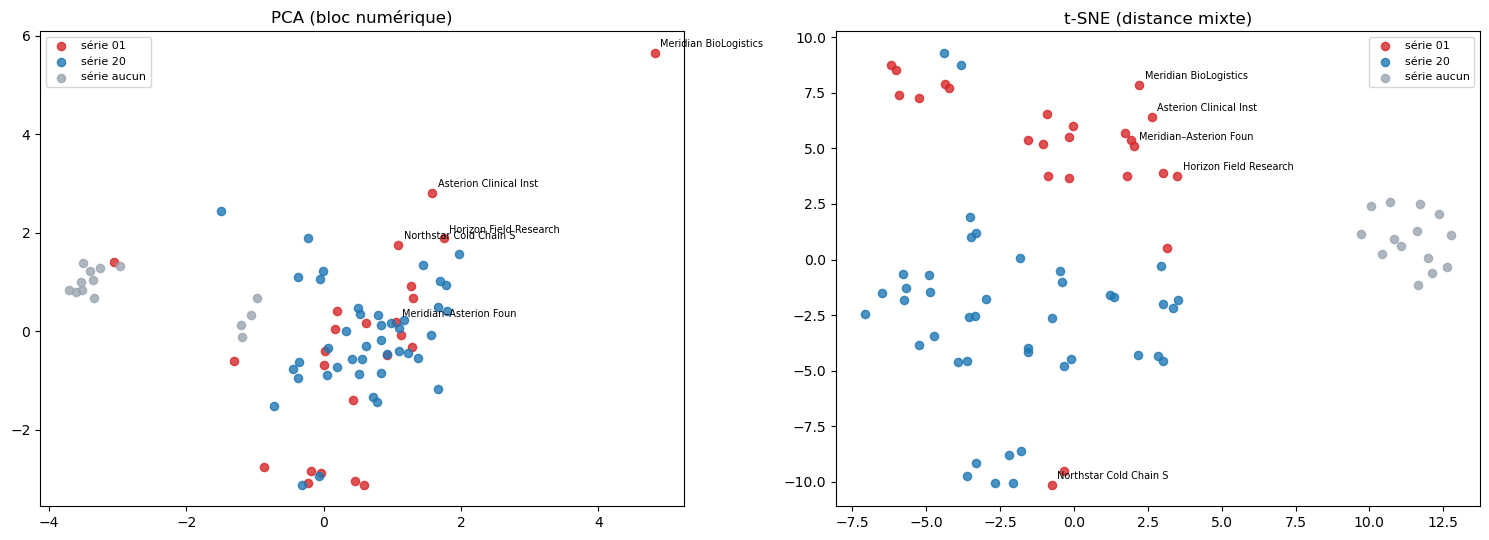

In [29]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

pca = PCA().fit(Xnum)
print("Variance expliquée :", pca.explained_variance_ratio_[:4].round(3), "| cumul 2 axes :",
      pca.explained_variance_ratio_[:2].sum().round(3))
print(pd.DataFrame(pca.components_[:2].T, index=Xnum.columns, columns=["PC1", "PC2"]).round(2).to_string())
P = pca.transform(Xnum)[:, :2]
T = TSNE(n_components=2, metric="precomputed", perplexity=15, init="random", random_state=0).fit_transform(D)

couleurs = {"01": "#d62728", "20": "#1f77b4", "aucun": "#9aa5b1"}
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, Y, titre in [(axes[0], P, "PCA (bloc numérique)"), (axes[1], T, "t-SNE (distance mixte)")]:
    for serie, coul in couleurs.items():
        m = (bp.reg_serie == serie).values
        ax.scatter(Y[m, 0], Y[m, 1], c=coul, label=f"série {serie}", s=35, alpha=.8)
    for i, c in enumerate(bp.partner_code):
        if c in ("BP-30078", "BP-30021", "BP-30056", "BP-30017", "BP-30047"):
            ax.annotate(noms[c][:22], Y[i], fontsize=7, xytext=(4, 4), textcoords="offset points")
    ax.set_title(titre); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

Les 2 premiers axes de la PCA expliquent 43,7 % de la variance, ce n'est pas une structure simple. Le premier axe correspond au volume de livraisons (réceptions, sites livrés, part vers le groupe des 10) et le deuxième à l'activité d'expédition (expéditions envoyées et reçues, sites exploités). Fournir des sites et s'expédier des marchandises sont donc deux activités indépendantes. Meridian est seule tout au bout des deux axes, et les partenaires sans numéro forment un petit groupe à gauche parce qu'ils ne livrent pas.

Sur le t-SNE on voit trois zones qui suivent la série du numéro : la série 20 en haut, la série 01 en bas à gauche, et les partenaires sans numéro à droite. C'est en partie à cause de la distance, puisque la série en fait partie, mais pas seulement, car la PCA (qui n'utilise pas la série) isole déjà les partenaires sans numéro. Meridian, Asterion, Horizon et la Meridian–Asterion Foundation sont voisins.

UMAP aurait pu remplacer le t-SNE, mais avec 80 points son avantage (la rapidité) ne sert à rien.

### 5.4 Regroupement

Ici c'est la distance qui impose les algorithmes. On prend un clustering hiérarchique avec liaison moyenne, parce qu'il accepte notre distance mixte (Ward, lui, ne marche qu'avec la distance euclidienne) et qu'avec 80 partenaires le dendrogramme reste lisible. On prend aussi K-medoids, qui ressemble à K-means sauf que le centre de chaque groupe est un vrai partenaire (le médoïde), ce qui permet d'utiliser n'importe quelle distance ; on l'a codé en quelques lignes et on choisit k avec la silhouette. Et on ajoute DBSCAN pour repérer les partenaires qui n'entrent dans aucun groupe.

Silhouette K-medoids : {2: np.float64(0.199), 3: np.float64(0.236), 4: np.float64(0.179), 5: np.float64(0.246), 6: np.float64(0.246), 7: np.float64(0.192), 8: np.float64(0.225)} -> k = 6
Médoïdes (partenaires « types ») : ['Marot Ecological Policy Office', 'Juniper Community Health Foundation', 'Avelora Council of State', 'Crescent Freight Exchange', 'Meridian–Asterion Foundation', 'Quartz Data Hosting']
Accord hiérarchique / K-medoids (Rand ajusté) : 0.64
DBSCAN (eps = 0.336) : 1 groupes, bruit = ['Meridian BioLogistics']


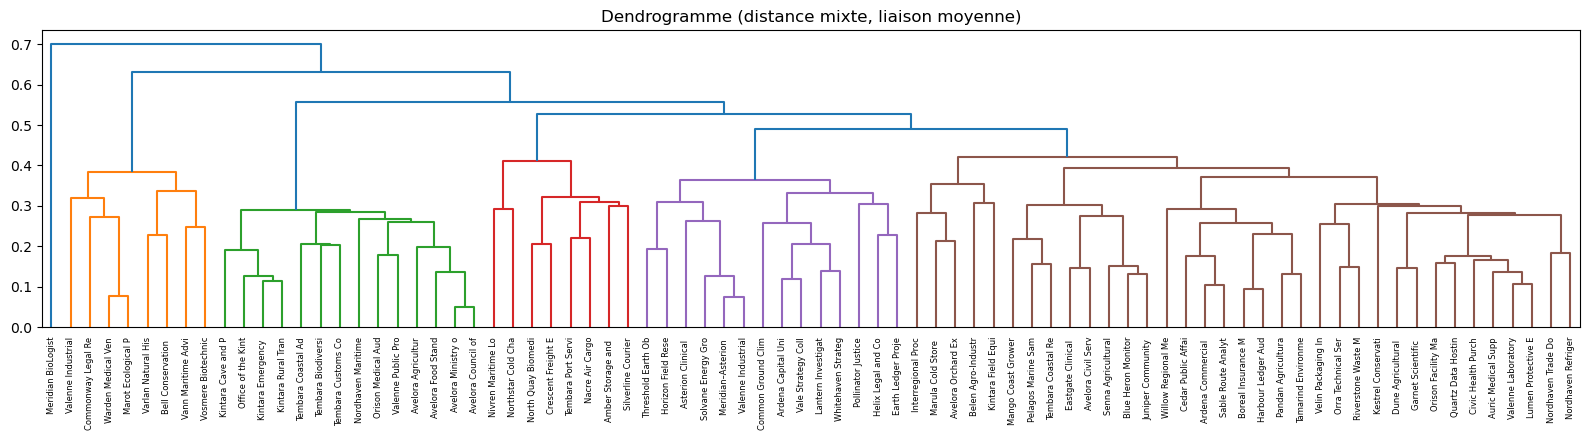

In [30]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.cluster import DBSCAN

def k_medoids(D, k, n_iter=100, seed=0):
    rng = np.random.default_rng(seed)
    med = rng.choice(len(D), k, replace=False)
    for _ in range(n_iter):
        lab = D[:, med].argmin(axis=1)
        nouveaux = np.array([np.where(lab == j)[0][D[np.ix_(lab == j, lab == j)].sum(axis=1).argmin()] for j in range(k)])
        if set(nouveaux) == set(med):
            break
        med = nouveaux
    return D[:, med].argmin(axis=1), med

sil = {}
for k in range(2, 9):
    best = min((k_medoids(D, k, seed=s) for s in range(10)), key=lambda r: D[np.arange(len(D)), r[1][r[0]]].sum())
    sil[k] = (silhouette_score(D, best[0], metric="precomputed"), best)
k_best = max(sil, key=lambda k: sil[k][0])
print("Silhouette K-medoids :", {k: round(v[0], 3) for k, v in sil.items()}, "-> k =", k_best)
bp["cl_kmedoids"], medoides = sil[k_best][1]
print("Médoïdes (partenaires « types ») :", [noms.iloc[m] for m in medoides])

Zh = linkage(squareform(D, checks=False), method="average")
bp["cl_hier"] = fcluster(Zh, k_best, criterion="maxclust")
print("Accord hiérarchique / K-medoids (Rand ajusté) :", round(adjusted_rand_score(bp.cl_hier, bp.cl_kmedoids), 2))
eps = float(np.quantile(np.sort(D, axis=1)[:, 4], 0.9))
bp["cl_dbscan"] = DBSCAN(eps=eps, min_samples=4, metric="precomputed").fit_predict(D)
print(f"DBSCAN (eps = {eps:.3f}) : {bp.cl_dbscan.max() + 1} groupes, bruit = "
      f"{bp.loc[bp.cl_dbscan == -1, 'partner_name'].tolist()}")

fig, ax = plt.subplots(figsize=(16, 4.5))
dendrogram(Zh, labels=[n[:18] for n in bp.partner_name], leaf_font_size=6, ax=ax, color_threshold=Zh[-k_best + 1, 2])
ax.set_title("Dendrogramme (distance mixte, liaison moyenne)"); plt.tight_layout(); plt.show()

In [31]:
profil = bp.groupby("cl_kmedoids").agg(
    n=("partner_code", "size"), role_dominant=("partner_role", lambda s: s.value_counts().index[0]),
    part_serie01=("reg_serie", lambda s: (s == "01").mean()), part_inactifs=("partner_status", lambda s: (s == "inactive").mean()),
    receptions_med=("nb_receptions_fournies", "median"), vers_groupe10=("part_vers_groupe10", "mean"),
    exp_envoyees=("nb_exp_envoyees", "median"), taux_incompletes=("taux_incompletes", "mean")).round(2)
print(profil.to_string())
print("\nSérie d'enregistrement × groupe :")
print(pd.crosstab(bp.cl_kmedoids, bp.reg_serie).to_string())

              n    role_dominant  part_serie01  part_inactifs  receptions_med  vers_groupe10  exp_envoyees  taux_incompletes
cl_kmedoids                                                                                                                 
0             8  service_partner          0.75            1.0             7.0           0.71           0.0              0.10
1            15         customer          0.07            0.0             8.0           0.79           5.0              0.12
2            13         customer          0.00            0.0             0.0           0.23           4.0              0.00
3            10          carrier          0.20            0.0             7.0           0.45           4.5              0.16
4            15  service_partner          1.00            0.0             7.0           0.73           5.0              0.07
5            19         supplier          0.00            0.0             7.0           0.72           4.0              0.08


6 groupes, silhouette faible (0,25) mais stables entre K-medoids et hiérarchique (ARI 0,64). Le groupe 0 réunit 8 inactifs qui livrent normalement. DBSCAN met Meridian seule à part.

| Groupe | Taille | Profil |
|---|---|---|
| 0 | 8 | tous inactifs (6 de la série 01), mais 7 réceptions en médiane, 71 % vers le groupe des 10 |
| 1 | 15 | clients de la série 20, livrent surtout le groupe des 10 |
| 2 | 13 | sans numéro (organismes publics), pas de livraison en médiane |
| 3 | 10 | transporteurs, le plus fort taux de réceptions incomplètes (16 %) |
| 4 | 15 | série 01 active, surtout des prestataires de services |
| 5 | 19 | fournisseurs de la série 20 |

---
## 6. Règles et anomalies
### 6.1 Règles d'association sur les profils

In [32]:
from utils.pattern_detection import itemsets_frequents, regles_association

med = bp.loc[bp.nb_receptions_fournies > 0, "nb_receptions_fournies"].median()
items = pd.DataFrame({
    "role": bp.partner_role, "risque": bp.risk_class, "serie": bp.reg_serie, "statut": bp.partner_status,
    "paiement": bp.payment_terms, "pays": bp.billing_region.str.split().str[0],
    "livraisons": np.select([bp.nb_receptions_fournies == 0, bp.nb_receptions_fournies <= med], ["aucune", "faibles"], "fortes"),
    "destination": np.where(bp.part_vers_groupe10 > 0.5, "groupe10_majoritaire", "autres_sites"),
    "expedie": np.where(bp.nb_exp_envoyees > 0, "oui", "non"),
})
transactions = [frozenset(f"{c}={v}" for c, v in r.items()) for r in items.to_dict("records")]
F = itemsets_frequents(transactions, min_support=0.05)
print(f"{len(transactions)} transactions, {len(F)} itemsets fréquents (support >= 5 %)")
supp = {x[0]: s for x, s in zip(F.itemset, F.support_rel) if len(x) == 1}
idx = F.set_index("itemset").support_rel
R_all = regles_association(F, min_confidence=0.5, min_lift=1.2, max_taille=4)
R_all["leverage"] = R_all.apply(lambda r: r.support_rel - idx[tuple(sorted(r.antecedent))] * supp[r.consequent[0]], axis=1)
for cible in ["serie=01", "risque=elevated", "destination=groupe10_majoritaire"]:
    r = R_all[R_all.consequent == (cible,)].sort_values(["lift", "support_abs"], ascending=False)
    print(f"\nRègles -> {cible} (support de base {supp.get(cible, 0):.2f}) :")
    print(r.head(6)[["antecedent", "support_abs", "confiance", "lift", "leverage"]].round(2).to_string(index=False)
          if len(r) else "  aucune règle avec confiance >= 0.5")

80 transactions, 1990 itemsets fréquents (support >= 5 %)

Règles -> serie=01 (support de base 0.30) :
                                                          antecedent  support_abs  confiance  lift  leverage
                                      (expedie=non, risque=standard)            5       0.83  2.78      0.04
                                  (risque=standard, statut=inactive)            5       0.83  2.78      0.04
    (destination=groupe10_majoritaire, expedie=non, risque=standard)            5       0.83  2.78      0.04
(destination=groupe10_majoritaire, risque=standard, statut=inactive)            5       0.83  2.78      0.04
                     (expedie=non, risque=standard, statut=inactive)            5       0.83  2.78      0.04
                               (livraisons=faibles, risque=elevated)            4       0.80  2.67      0.03

Règles -> risque=elevated (support de base 0.11) :
  aucune règle avec confiance >= 0.5

Règles -> destination=groupe10_majoritaire (

In [33]:
print(pd.crosstab(items.serie, items.destination, margins=True).to_string())
print()
print(pd.crosstab(items.serie, items.livraisons, margins=True).to_string())

destination  autres_sites  groupe10_majoritaire  All
serie                                               
01                      4                    20   24
20                      9                    33   42
aucun                  10                     4   14
All                    23                    57   80

livraisons  aucune  faibles  fortes  All
serie                                   
01               1       13      10   24
20               0       21      21   42
aucun           10        4       0   14
All             11       38      31   80


On obtient 1 990 combinaisons fréquentes, parce que beaucoup d'éléments sont très courants, donc il faut trier par conclusion et par lift.

Vers la série 01 (30 % des partenaires au départ), la règle « risque standard + inactif » donne la série 01 dans 83 % des cas (lift 2,78, 5 partenaires sur 6), ce qui veut dire que les inactifs sont surtout des entreprises du registre public. « Risque élevé + peu de livraisons » donne aussi la série 01 dans 80 % des cas. Par contre on ne trouve aucune règle vers le risque élevé : le risque attribué par Meridian ne s'explique ni par les attributs ni par l'activité. Vers le groupe des 10 (71 % au départ), il y a plusieurs règles à 100 % mais avec un lift de seulement 1,4, parce que presque tout le monde livre surtout le groupe des 10 (20 partenaires sur 24 en série 01, 33 sur 42 en série 20).

Ces règles reposent sur 4 à 11 partenaires, il faut donc les voir comme des pistes.

On a gardé l'Apriori de mon binôme car FP-Growth donnerait exactement les mêmes résultats et n'est utile que sur de grosses bases. Le lift est indispensable ici, parce que la confiance seule met en avant des conclusions qui sont déjà fréquentes.

### 6.2 Anomalies

Sur une variable, on applique le z-score et le z-score modifié au nombre de réceptions. Comme une valeur extrême gonfle le z-score classique, la version avec la médiane est plus fiable ici.

Sur plusieurs variables, on compare deux méthodes qui fonctionnent différemment. LOF accepte notre distance mixte et repère les partenaires qui sont dans une zone peu dense. Isolation Forest n'a pas besoin de distance, il isole les points par des coupes aléatoires, ce qui marche bien pour trouver des combinaisons rares.

In [34]:
from sklearn.neighbors import LocalOutlierFactor
from sklearn.ensemble import IsolationForest

s = bp.nb_receptions_fournies
z = (s - s.mean()) / s.std()
zm = 0.6745 * (s - s.median()) / (s - s.median()).abs().median()
print("z > 3 :", bp.loc[z > 3, "partner_name"].tolist(), "| z modifié > 3.5 :", bp.loc[zm > 3.5, "partner_name"].tolist())

lof = LocalOutlierFactor(n_neighbors=10, metric="precomputed").fit(D)
bp["lof"] = -lof.negative_outlier_factor_
Xenc = pd.concat([Xnum.reset_index(drop=True), pd.get_dummies(bp[nominales]).astype(int).reset_index(drop=True)], axis=1)
bp["iforest"] = -IsolationForest(random_state=0).fit(Xenc).score_samples(Xenc)
bp["rang_lof"] = bp.lof.rank(ascending=False)
bp["rang_iforest"] = bp.iforest.rank(ascending=False)
top = bp.assign(rang_moyen=(bp.rang_lof + bp.rang_iforest) / 2).nsmallest(8, "rang_moyen")
print(top[["partner_code", "partner_name", "partner_role", "reg_serie", "partner_status", "nb_receptions_fournies",
           "nb_exp_envoyees", "nb_exp_recues", "lof", "rang_lof", "rang_iforest"]].round(2).to_string(index=False))
print("\nCorrélation de Spearman entre les deux scores :", round(bp.lof.corr(bp.iforest, method="spearman"), 2))

z > 3 : ['Meridian BioLogistics'] | z modifié > 3.5 : ['Horizon Field Research Cooperative', 'Meridian BioLogistics']
partner_code                         partner_name      partner_role reg_serie partner_status  nb_receptions_fournies  nb_exp_envoyees  nb_exp_recues  lof  rang_lof  rang_iforest
    BP-30078                Meridian BioLogistics           carrier        01         active                     109               90             56 1.43       1.0           1.0
    BP-30026 Valenne Industrial Supply Consortium          customer        20       inactive                       7                0              0 1.19       3.0           6.0
    BP-30034    Commonway Legal Registry Services   service_partner        20       inactive                       7                0              0 1.18       5.0           4.0
    BP-30022        Varlan Natural History Circle          customer        01       inactive                      10                0              0 1.13       9.0       

En premier Meridian, puis des partenaires inactifs qui livrent et deux transporteurs atypiques. LOF et Isolation Forest sont assez d'accord (Spearman 0,66).

---
## 7. Réseau et processus

### 7.1 Qui expédie à qui ?

La table `shipments` relie directement deux partenaires, l'expéditeur et le destinataire. On construit donc un graphe orienté de l'expéditeur vers le destinataire, pondéré par le nombre d'expéditions.

In [35]:
import networkx as nx

lien = sh.groupby(["sender_partner_code", "receiver_partner_code"]).size().reset_index(name="poids")
G = nx.DiGraph()
G.add_nodes_from(bp.partner_code)
for _, r in lien.iterrows():
    G.add_edge(r.sender_partner_code, r.receiver_partner_code, weight=r.poids)
N, L = G.number_of_nodes(), G.number_of_edges()
print(f"N = {N}, L = {L}, densité = L / (N(N-1)) = {L / (N * (N - 1)):.4f}")
print("Boucles (un partenaire qui s'expédie à lui-même) :", [(u, G[u][v]["weight"]) for u, v in nx.selfloop_edges(G)])
deg = pd.DataFrame({"deg_sortant": dict(G.out_degree()), "deg_entrant": dict(G.in_degree()),
                    "force_sortante": dict(G.out_degree(weight="weight")),
                    "force_entrante": dict(G.in_degree(weight="weight"))})
deg["nom"] = deg.index.map(noms)
print(deg.sort_values("force_sortante", ascending=False).head(6).to_string())
print(deg.sort_values("force_entrante", ascending=False).head(6)[["nom", "force_entrante", "deg_entrant"]].to_string())
print("\nSources pures (n'envoient que) :", int(((deg.deg_entrant == 0) & (deg.deg_sortant > 0)).sum()),
      "| puits purs (ne reçoivent que) :", int(((deg.deg_sortant == 0) & (deg.deg_entrant > 0)).sum()),
      "| isolés :", int(((deg.deg_sortant == 0) & (deg.deg_entrant == 0)).sum()))

N = 80, L = 334, densité = L / (N(N-1)) = 0.0528
Boucles (un partenaire qui s'expédie à lui-même) : []
          deg_sortant  deg_entrant  force_sortante  force_entrante                                 nom
BP-30078           20           21              90              56               Meridian BioLogistics
BP-30056            3            6              35              20  Horizon Field Research Cooperative
BP-30010            9            4               9               5      Tembara Coastal Administration
BP-30017            9            6               9               6        Meridian–Asterion Foundation
BP-30068            7            3               7               3   Tamarind Environmental Law Centre
BP-30004            7            5               7               5         Common Ground Climate Forum
                                         nom  force_entrante  deg_entrant
BP-30021         Asterion Clinical Institute              58            3
BP-30078               Merid

In [36]:
print("Les 8 liens les plus lourds :")
for _, r in lien.sort_values("poids", ascending=False).head(8).iterrows():
    print(f"  {r.poids:3d}  {noms[r.sender_partner_code]} -> {noms[r.receiver_partner_code]}")

# Assortativité : un nœud est-il relié à des nœuds qui lui ressemblent ?
nx.set_node_attributes(G, bp.set_index("partner_code").reg_serie.to_dict(), "serie")
print("\nAssortativité selon la série d'enregistrement :",
      round(nx.attribute_assortativity_coefficient(G, "serie"), 3))
m = pd.crosstab(lien.sender_partner_code.map(bp.set_index("partner_code").reg_serie),
                lien.receiver_partner_code.map(bp.set_index("partner_code").reg_serie),
                values=lien.poids, aggfunc="sum").fillna(0).astype(int)
print("Expéditions par série d'expéditeur (lignes) et de destinataire (colonnes) :")
print(m.to_string())

Les 8 liens les plus lourds :
   56  Meridian BioLogistics -> Asterion Clinical Institute
   33  Horizon Field Research Cooperative -> Meridian BioLogistics
   15  Meridian BioLogistics -> Horizon Field Research Cooperative
    2  Meridian BioLogistics -> Eastgate Clinical Services
    2  Ardena Capital Union -> Nivren Maritime Logistics
    2  Sable Route Analytics -> Meridian BioLogistics
    2  Boreal Insurance Mutual -> Meridian BioLogistics
    2  Tembara Customs Coordination Unit -> Quartz Data Hosting

Assortativité selon la série d'enregistrement : 0.003
Expéditions par série d'expéditeur (lignes) et de destinataire (colonnes) :
receiver_partner_code   01  20  aucun
sender_partner_code                  
01                     133  46     20
20                      60  90     39
aucun                   20  28     14


Meridian est au centre. Le triangle Meridian → Asterion / Horizon représente 23 % des expéditions, et Asterion reçoit 56 de ses 58 expéditions de Meridian.

### 7.2 Nœuds centraux et communautés

Comme pour les réceptions, on calcule la betweenness pour trouver les ponts et on utilise Louvain pour les communautés (rapide et il prend en compte les poids, alors que Girvan-Newman serait trop lent et les ignore). Pour ce calcul on enlève le sens des liens et les boucles.

In [37]:
Gu = nx.Graph(G.to_undirected())
Gu.remove_edges_from(nx.selfloop_edges(Gu))
Gu.remove_nodes_from([n for n in list(Gu) if Gu.degree(n) == 0])
btw = pd.Series(nx.betweenness_centrality(Gu)).sort_values(ascending=False)
print("Betweenness (5 premiers) :", {noms[k]: round(v, 3) for k, v in btw.head(5).items()})
com = nx.community.louvain_communities(Gu, weight="weight", seed=0)
print(f"Louvain : {len(com)} communautés, Q = {nx.community.modularity(Gu, com, weight='weight'):.3f}")
serie = bp.set_index("partner_code").reg_serie
for i, c in enumerate(sorted(com, key=len, reverse=True)):
    s = serie[list(c)].value_counts().to_dict()
    print(f"  C{i} ({len(c)} partenaires, séries {s}) : {', '.join(sorted(noms[x][:20] for x in c)[:8])}{' …' if len(c) > 8 else ''}")

Betweenness (5 premiers) : {'Meridian BioLogistics': 0.168, 'Nordhaven Refrigeration Works': 0.05, 'Earth Ledger Project': 0.037, 'Meridian–Asterion Foundation': 0.035, 'Lantern Investigative Bureau': 0.034}
Louvain : 6 communautés, Q = 0.368
  C0 (17 partenaires, séries {'20': 7, 'aucun': 6, '01': 4}) : Auric Medical Suppli, Avelora Food Standar, Avelora Orchard Expo, Belen Agro-Industrie, Dune Agricultural Ma, Kintara Cave and Pol, Kintara Rural Transp, Lumen Protective Equ …
  C1 (17 partenaires, séries {'20': 10, '01': 5, 'aucun': 2}) : Ardena Capital Union, Avelora Council of S, Kestrel Conservation, Kintara Emergency Re, Kintara Field Equipm, Lantern Investigativ, Nacre Air Cargo, Nivren Maritime Logi …
  C2 (15 partenaires, séries {'20': 8, '01': 4, 'aucun': 3}) : Avelora Agricultural, Blue Heron Monitorin, Boreal Insurance Mut, Cedar Public Affairs, Earth Ledger Project, Garnet Scientific In, Helix Legal and Comp, Marula Cold Store Co …
  C3 (11 partenaires, séries {'20': 9, '0

Meridian est le seul vrai pont. Louvain (modularité 0,37) isole exactement le triangle Meridian, Asterion, Horizon.

### 7.3 Comment vit un partenaire ?

Pour chaque partenaire, on met ses événements dans l'ordre : `commande` (il reçoit une commande), `livraison` (ses marchandises arrivent), `expedition_envoyee`, `expedition_recue` et `transport` (il transporte une expédition). On fusionne les répétitions (« livraison, livraison, livraison » devient « livraison »), puis on compte les enchaînements et on calcule la dépendance de l'Heuristic Miner.

In [38]:
po["order_date"] = convertir_date(po.order_date)
ev = pd.concat([
    po[["supplier_partner_code", "order_date"]].set_axis(["partenaire", "date"], axis=1).assign(activite="commande"),
    gr[["supplier_partner_code", "receipt_date"]].set_axis(["partenaire", "date"], axis=1).assign(activite="livraison"),
    sh[["sender_partner_code", "dispatch_time"]].set_axis(["partenaire", "date"], axis=1).assign(activite="expedition_envoyee"),
    sh[["receiver_partner_code", "dispatch_time"]].set_axis(["partenaire", "date"], axis=1).assign(activite="expedition_recue"),
    sh[["carrier_partner_code", "dispatch_time"]].set_axis(["partenaire", "date"], axis=1).assign(activite="transport"),
]).dropna().sort_values(["partenaire", "date"])
traces = {}
for p, g in ev.groupby("partenaire"):
    a = g.activite.tolist()
    traces[p] = ["DEBUT"] + [x for i, x in enumerate(a) if i == 0 or x != a[i - 1]] + ["FIN"]
print(f"{len(ev)} événements, {len(traces)} partenaires actifs")

paires = pd.Series([(a, b) for t in traces.values() for a, b in zip(t, t[1:])]).value_counts()
acts = sorted({x for t in traces.values() for x in t})
DF = pd.DataFrame(0, index=acts, columns=acts)
for (a, b), c in paires.items():
    DF.loc[a, b] = c
dep = (DF - DF.T) / (DF + DF.T + 1)
print("\nMatrice des enchaînements directs :")
print(DF.to_string())
print("\nDépendances >= 0,5 (Heuristic Miner) :")
print(dep.stack()[lambda s: s >= 0.5].round(2).to_string())

2610 événements, 80 partenaires actifs

Matrice des enchaînements directs :
                    DEBUT  FIN  commande  expedition_envoyee  expedition_recue  livraison  transport
DEBUT                   0    0        29                  19                26          0          6
FIN                     0    0         0                   0                 0          0          0
commande                0    1         0                  76                63        385         33
expedition_envoyee      0   21       142                   0               101         54         39
expedition_recue        0   15       124                 108                 0         50         34
livraison               0   40       214                 120               102          0         38
transport               0    3        49                  34                39         25          0

Dépendances >= 0,5 (Heuristic Miner) :
DEBUT               commande              0.97
                    expeditio

In [39]:
# Longueur des traces par série : quels partenaires ont l'activité la plus « variée » ?
bp["longueur_trace"] = bp.partner_code.map({p: len(t) - 2 for p, t in traces.items()}).fillna(0)
print(bp.groupby("reg_serie").longueur_trace.describe()[["count", "mean", "50%", "max"]].round(1).to_string())
t = traces["BP-30078"][1:-1]
print(f"\nTrace compressée de Meridian : {len(t)} étapes ; début : {' → '.join(t[:8])} …")

           count  mean   50%    max
reg_serie                          
01          24.0  35.6  20.0  330.0
20          42.0  22.9  22.5   40.0
aucun       14.0   6.6   6.5   11.0

Trace compressée de Meridian : 330 étapes ; début : commande → livraison → expedition_envoyee → expedition_recue → commande → livraison → transport → commande …


Pas d'ordre fixe entre les activités, donc pas de parcours type pour un partenaire.

---
## Synthèse

Les 80 partenaires se divisent en trois séries de numéros. La série 01 correspond exactement aux 24 entreprises du registre public.

Les rôles déclarés dans l'ERP ne correspondent pas à l'activité : Meridian, déclarée transporteur, est le premier fournisseur, et des clients livrent des marchandises.

Le regroupement isole 8 partenaires inactifs qui livrent quand même, et Meridian, qui ne ressemble à personne.

Dans le réseau, le triangle Meridian / Asterion / Horizon fait 23 % des expéditions.

Avec seulement 80 partenaires, certains résultats reposent sur peu de cas.